# Advanced QC of Image-based technologies

## Environment set up and Data 

We will analyze the [10x Xenium breast cancer data](https://www.10xgenomics.com/products/xenium-in-situ/preview-dataset-human-breast), which includes supervised cell type annotations provided by 10x Genomics ([Janesick et al. 2023](https://doi.org/10.1038/s41467-023-43458-x)). 
These annotations will be used to evaluate the expression of positive and negative marker genes, thereby validating expected patterns of cell type–specific expression. 
In addition, we will use the celltype annotation to check some of the QC metrics.

The dataset can be downloaded in SpatialData format as illustrated in this [notebook](../data_loading/breast_cancer_xenium.ipynb).

The dataset comprises 5-µm formalin-fixed paraffin-embedded (FFPE) breast cancer tissue sections profiled with a 313-gene panel and includes two HER2-positive samples with distinct hormone receptor profiles and histopathological features, including ductal carcinoma in situ (DCIS), invasive carcinoma and normal ductal regions. 
Xenium measurements were complemented by post-Xenium immunofluorescence imaging (DAPI, CD20 and HER2) and H&E staining and were integrated in the original study with matched Chromium and Visium measurements.
For Xenium Sample 1, both supervised cell-type annotations transferred from matched single-cell data and unsupervised annotations are publicly available.
Sample 1 comprises two replicate 5-µm tissue sections.
In this tutorial, we use the first replicate together with the supervised cell-type annotations to evaluate transcript-, segmentation- and image-level QC metrics.

As a first step, we load the dataset with `spatialdata`, which is hosted on Figshare.

In [34]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import geopandas as gpd
import seaborn as sns
import re
import ovrlpy
import matplotlib.image as mpimg
import cv2
import plotly.express as px
import concurrent.futures

#import spatialdata as sd
import matplotlib.pyplot as plt
import spatialdata as sd
import spatialdata_plot
import scanpy as sc
import lamindb as ln

from tqdm.auto import tqdm
from esda.moran import Moran
from libpysal.weights import Queen

## General settings

In [35]:
FIGURE_FORMATE = "pdf"
THREADS = 8

## Function definitions

These are all just functions to generate some plots we will need to inspect the quality of the data.

In [ ]:
from spoqc import helperfuncs

## Data loading

### Selection of the image
Image-based methods typically produce multiple image files.
Before proceeding, it is important to review what each image represents.
The official [10x Genomics documentation](https://www.10xgenomics.com/support/software/xenium-onboard-analysis/1.9/analysis/xoa-output-understanding-outputs) provides a detailed description of the outputs included in a Xenium data bundle.
For this tutorial, we will focus on the **2D autofocus projection** of the tissue morphology image, which is well-suited for assessing image quality.

### Image resolution
All image-based methods provide outputs at different resolutions.
For quality assessment, we will use the highest available resolution.

We will explore the different layers of the spatial data. 
To follow along, please review the description of these layers in this [tutorial](https://spatialdata.scverse.org/en/stable/tutorials/notebooks/notebooks/examples/intro.html).

In [37]:
IMAGE = 'morphology_focus'
RESOLUTION = 'scale0'
KEY_TRANSCRIPTS = 'transcripts'
ANNOTATION_KEY = 'celltype'

sdata = ln.Artifact.using("theislab/sc-best-practices").get("jrWZV2PVxiPhM5lt0000").load()

In [39]:
sdata['table']

AnnData object with n_obs × n_vars = 167780 × 313
    obs: 'cell_id', 'transcript_counts', 'control_probe_counts', 'control_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'region', 'celltype'
    var: 'gene_ids', 'feature_types', 'genome'
    uns: 'spatialdata_attrs'
    obsm: 'spatial'

### Downsampling
We will crop the data to speed up the demonstrations, because some of the code need lots of memory and more time to compute on a local machine.

In [40]:
sdata_filtered_cs = sdata.filter_by_coordinate_system('global')
cropped_sdata = sdata_filtered_cs.query.bounding_box(
    axes=["x", "y"],
    min_coordinate=[12000, 12000],
    max_coordinate=[16000, 16000],
    target_coordinate_system='global',
)

# This has to be done because else those levels have different cell_ids captures.
ids = [int(x) for x in cropped_sdata['table'].obs.index.tolist()]
cropped_sdata['cell_boundaries'] = sdata['cell_boundaries'].loc[ids]
cropped_sdata['nucleus_boundaries'] = sdata['nucleus_boundaries'].loc[ids]

sdata = cropped_sdata

In [41]:
sdata

SpatialData object
├── Images
│     ├── 'morphology_focus': DataTree[cyx] (1, 4000, 4000), (1, 2000, 2000), (1, 1000, 1000), (1, 500, 500), (1, 250, 250)
│     └── 'morphology_mip': DataTree[cyx] (1, 4000, 4000), (1, 2000, 2000), (1, 1000, 1000), (1, 500, 500), (1, 250, 250)
├── Labels
│     ├── 'cell_labels': DataTree[yx] (4000, 4000), (2000, 2000), (1000, 1000), (500, 500), (250, 250)
│     └── 'nucleus_labels': DataTree[yx] (4000, 4000), (2000, 2000), (1000, 1000), (500, 500), (250, 250)
├── Points
│     └── 'transcripts': DataFrame with shape: (<Delayed>, 8) (3D points)
├── Shapes
│     ├── 'cell_boundaries': GeoDataFrame shape: (3296, 1) (2D shapes)
│     ├── 'cell_circles': GeoDataFrame shape: (3296, 2) (2D shapes)
│     └── 'nucleus_boundaries': GeoDataFrame shape: (3296, 1) (2D shapes)
└── Tables
      └── 'table': AnnData (3296, 313)
with coordinate systems:
    ▸ 'global', with elements:
        morphology_focus (Images), morphology_mip (Images), cell_labels (Labels), nucleus

Let's first visualize the data and used the aforemention **2D autofocus projection** of the tissue morphology image.

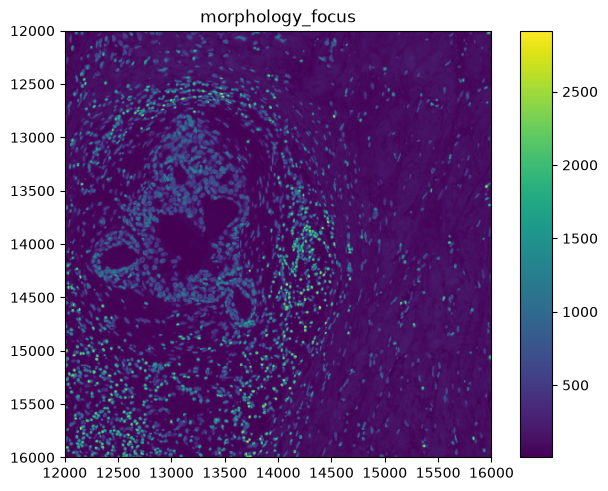

In [42]:
sdata.pl.render_images(IMAGE).pl.show(title=IMAGE)

The image shows clear tissue structures: a dense region on the left, potentially originating from the breast ductal system, and some scattered cells visible on the right side.
However, based on morphology alone, it is difficult to determine which cells or regions are of high or low quality.
Let’s investigate this further.

(advanced-qc-advanced-qc-key-takeaway-1)=

## Level 1: Single-molecule

Note that, depending on the spatial technology, this layer represents different objects (e.g., individual molecules or spots), which can be broadly referred to as spatial observations.
As a first step, we will examine the transcript locations to identify potential artifacts.
Thus, let's generate an overview of the locations of our transcript in the data.

To assess whether transcripts are detected inside or outside cells, we will use the information stored in `sdata.points.['transcripts']`. 
Specifically, we will rely on the columns `cell_id` and `overlaps_nucleus`. 
For Xenium a value of `cell_id = -1` indicates that a transcript is not associated with any cell ([see the 10xBaysor tutorial](https://www.10xgenomics.com/analysis-guides/using-baysor-to-perform-xenium-cell-segmentation)). 
Other technologies might use a different indicator for these transcripts.

In [43]:
# If a transcript is NOT associated with a cell, it will get -1.
# If it is associated with a cell, this column will have a positive integer cell ID.
cell_id = list(sdata.points[KEY_TRANSCRIPTS]['cell_id'])
in_nucleus = list(sdata.points[KEY_TRANSCRIPTS]['overlaps_nucleus'])

# Where are those transcripts located (more in the nucleus, cytoplasm)?
# Pie chart for transcripts in cytoplasm, in nucleus, outside cell
location_list = np.array(['Outside Cell' if x == -1 else 'In Cell' for x in cell_id])

for i in range(0, len(cell_id)):

    if ( location_list[i] == 'In Cell' and in_nucleus[i] == 0 ):
        location_list[i] = 'In Nucleus'

counter_in_cell = len([x for x in cell_id if x != -1])
counter_outside_cell = len([x for x in cell_id if x == -1])
counter_in_nucleus = len([x for x in in_nucleus if x == 0])

d = pd.DataFrame({'total': ['Total'] * 3,
    'in_vs_out_cell': ['In Cell', 'In Cell', 'Outside Cell'],
    'in_nucleus': ['Nucleus', 'Cytoplasm', 'Outside Cell'],
    'counts': [counter_in_nucleus, counter_in_cell, counter_outside_cell]})

fig = px.sunburst(d, path=['total', 'in_vs_out_cell', 'in_nucleus'], values='counts')
fig.update_traces(textinfo="label+value+percent entry", textfont=dict(size=18))
fig.update_traces(marker_colors=["lightblue","lightgreen","red","green","red"])
fig.show()

In this dataset, we observe 1,263,671 captured transcripts. 
The inner circle indicates whether transcripts are located inside cells (green) or outside cells (red).
With only ~3% of transcripts outside cells, we can be confident that there are no major segmentation issues.

However, it could be that those ~3% are located in specific areas, which is why we have to go deeper.

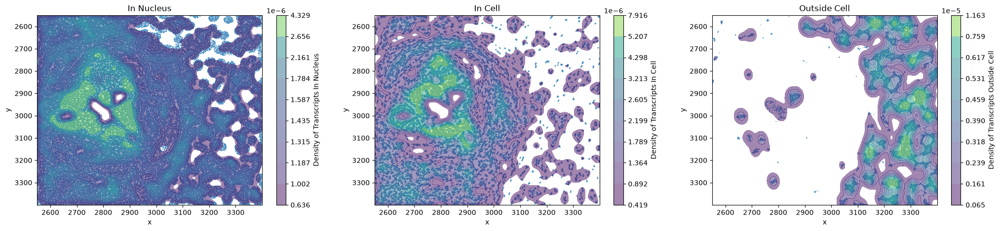

In [ ]:
# This plot will take about 10 min to generate. This is one of the slowest plots in the tutorial.
df = sdata[KEY_TRANSCRIPTS].compute()
df['location'] = location_list
df['qv_binary'] = (df['qv'] < 20).astype(int)
df[ANNOTATION_KEY] = sdata['table'].obs[ANNOTATION_KEY]
helperfuncs.plot_spatial_density_of_category(df, 'location', 'location', None, 'Transcript Quality Density', category='location', cbar_title='Density of Transcripts', pointsize=1.0, figsize=(25, 5))

We can clearly observe that regions outside the dense tissue contain a higher proportion of transcripts unassigned to cells (right panel), indicating lower-quality areas. 
Additionally, some holes within the tissue also show unassigned transcripts. 
These transcripts may be suitable for reassignment using tools such as {cite:p}`spat:heidari2025segger`.

Let's check using quality measurement of the transcripts if locations populated with many transcripts outside the cell correlated with low quality regions.
We will use the `qv` column in `sdata.points.['transcripts']`, which represents the phred-scaled quality score for each transcript.
Be aware that this is Xenium-specific, and other technologies might use different confidence measures.
10x Genomics typically uses a threshold of < 20 ([see the 10xBaysor tutorial](https://www.10xgenomics.com/analysis-guides/using-baysor-to-perform-xenium-cell-segmentation)).


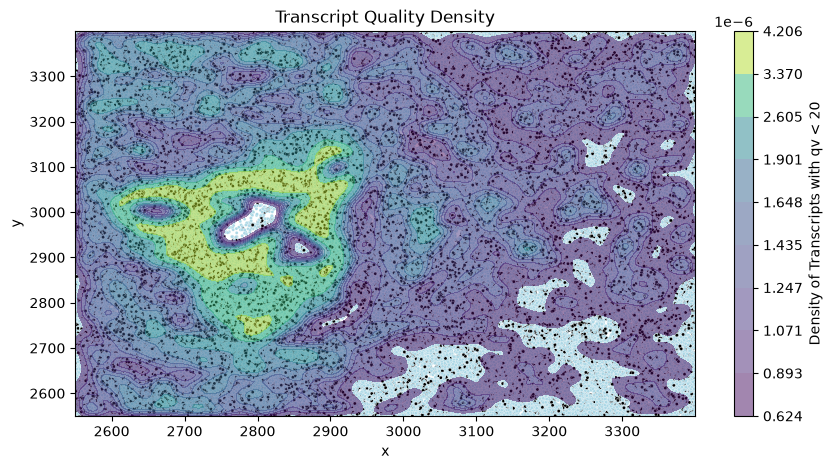

In [ ]:
# This plot will take about 10 min to generate. This is one of the slowest plots in the tutorial.
helperfuncs.plot_spatial_density_of_category(df, 'qv_binary', 'qv_binary', ['lightblue', 'black'], 'Transcript Quality Density', plot_legend=False, cbar_title='Density of Transcripts with qv < 20', pointsize=5.0)

Regions with high density indicate areas where many transcript calls are unreliable.
As observed, some lower-quality transcripts are located in the right-side region that we previously identified.

The high-cell-density region on the left also contains many low-quality transcripts.
It would be wise to examine this region as well.

Since cell type annotations are available, we can now investigate whether this effect is cell type–specific.

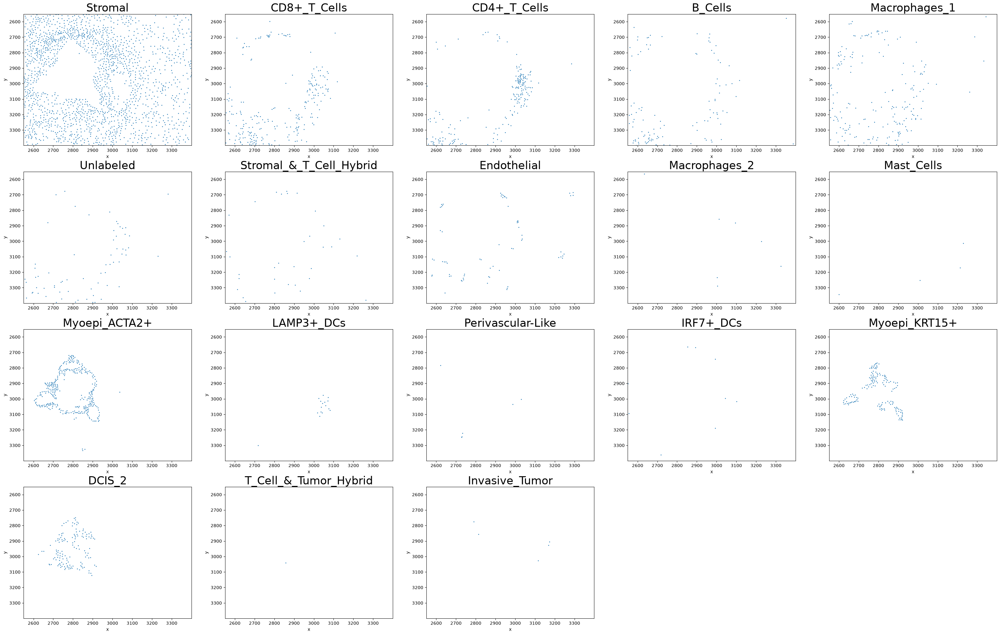

In [ ]:
helperfuncs.plot_spatial_density_of_category(sdata['table'], ANNOTATION_KEY, None, None, 'Celltypes', category=ANNOTATION_KEY, pointsize=5.0, figsize=(40,25), title_text_size=25)

Indeed, when compared with the previous plot, we observe a high proportion of lower-quality transcripts in regions corresponding to myoepithelial and stromal cells.
Thus, we have to be careful with these celltypes.

### Negative Control Probes

It is also wise to check the spatial pattern of **"negative control probes"**. 
Be careful with the term. 
Sometimes technologies have a different name for **negative control probes**.
For Xenium negative control probes are valid codewords that correspond to probes targeting sequences that should not be present in the sample.
Thus, we would expect to see some random spatial patterns, if they occur.

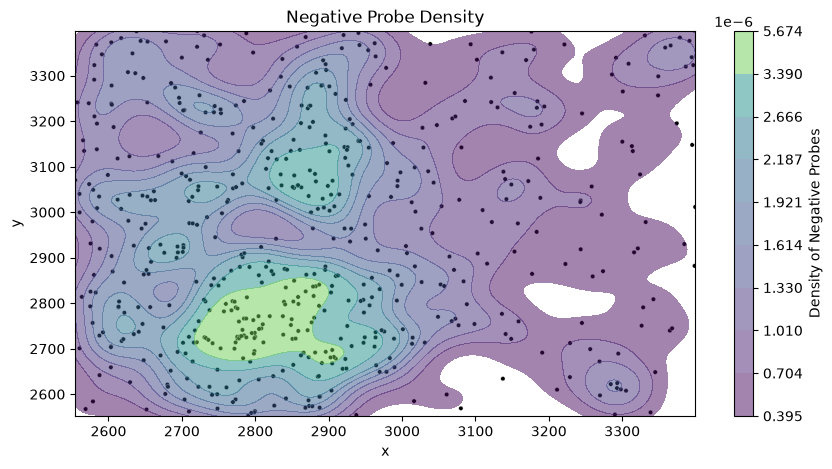

In [ ]:
match_neg_probes = [bool(re.compile('NegControlCodeword').match(x)) for x in list(df['feature_name'])]
df['neg_probes'] = match_neg_probes
helperfuncs.plot_spatial_density_of_category(df[df['neg_probes'] == True], 'neg_probes', None, ['black'], 'Negative Probe Density', cbar_title='Density of Negative Probes', plot_legend=False, pointsize=10, figsize=(10, 5))

The negative control probes are almost scattered randomly across the tissue. 
We can see a dense area in the lower half of the tissue. 
This area has to be treated with caution as it is also overlapping with a high population of lower quality transcripts.

(advanced-qc-advanced-qc-key-takeaway-2)=

### Doublet detection

Although we conceptually treat the tissue section as a flat 2D tissue slice, it is actually a 5-15 µm-thick volume, imaged as a z-stack of multiple focal planes to capture transcripts throughout its depth {cite:p}`spat:tiesmeyer2026identifying`.
Because segmentation collapses this z-stack into a single 2D footprint per cell, two different cells positioned at different depths within the section can overlap in their xy projection and be merged into one segmented object, a so-called doublet.

Be aware that this QC step might be technology-dependent, as some technologies do not report a z-coordinate because storing this information would consume too much hardware space.

The following steps can be run on the downsampled dataset, but note that the results may be less informative. 
For this reason, we will present outputs based on the full dataset. 
Keep in mind, however, that processing the full dataset can take longer, making it less suitable for a quick tutorial.

First, we need to detect doublets. For this purpose, we will use the tool ovrlpy {cite:p}`spat:tiesmeyer2026identifying`.

In [48]:
cell_diameter = np.mean(sdata['cell_circles']['radius'])*2
n_expected_celltypes = 3 # Since we have cropped the data, we have for some cell types not enough representatives.
minimum_signal_strength = 3
integrity_sigma = 2
signal_threshold = 3
window_sizes = [10, 60]
num_doublet = 1
distance = 10

transcript_coordinates_df = sdata.points[KEY_TRANSCRIPTS].compute()
transcript_coordinates_df = transcript_coordinates_df.rename(columns={'feature_name': 'gene'})

# In an older version ovrlpy to overwrote the coordinates and set the origin to 0.0.
# Thus to bring the doublet coordinates into the original data points coord system we have to save the origin.
min_x = min(transcript_coordinates_df['x'])
min_y = min(transcript_coordinates_df['y'])

n_components = 30
if (n_expected_celltypes and n_expected_celltypes > 0):
    n_components = n_expected_celltypes
if ( sdata['table'].n_obs < 500 ):
    n_components = 10
if ( sdata['table'].n_obs < 100 ):
    n_components = 2

ovrlp = ovrlpy.Ovrlp(
    transcript_coordinates_df,
    min_distance=cell_diameter,
    n_components=n_components,
)
ovrlp.analyse()

doublet_df = ovrlp.detect_doublets(
    min_signal=minimum_signal_strength,
    integrity_sigma=integrity_sigma,
).to_pandas()

Running vertical adjustment
Creating gene expression embeddings for visualization
determining pseudocells
found 517 pseudocells
sampling expression:


100%|██████████| 1/1 [00:05<00:00,  5.33s/it]


Modeling 3 pseudo-celltype clusters;
Creating signal integrity map


100%|██████████| 4/4 [00:13<00:00,  3.36s/it]



Now that we have identified the doublets, we can begin by examining how the transcript patterns appears across different z-levels.

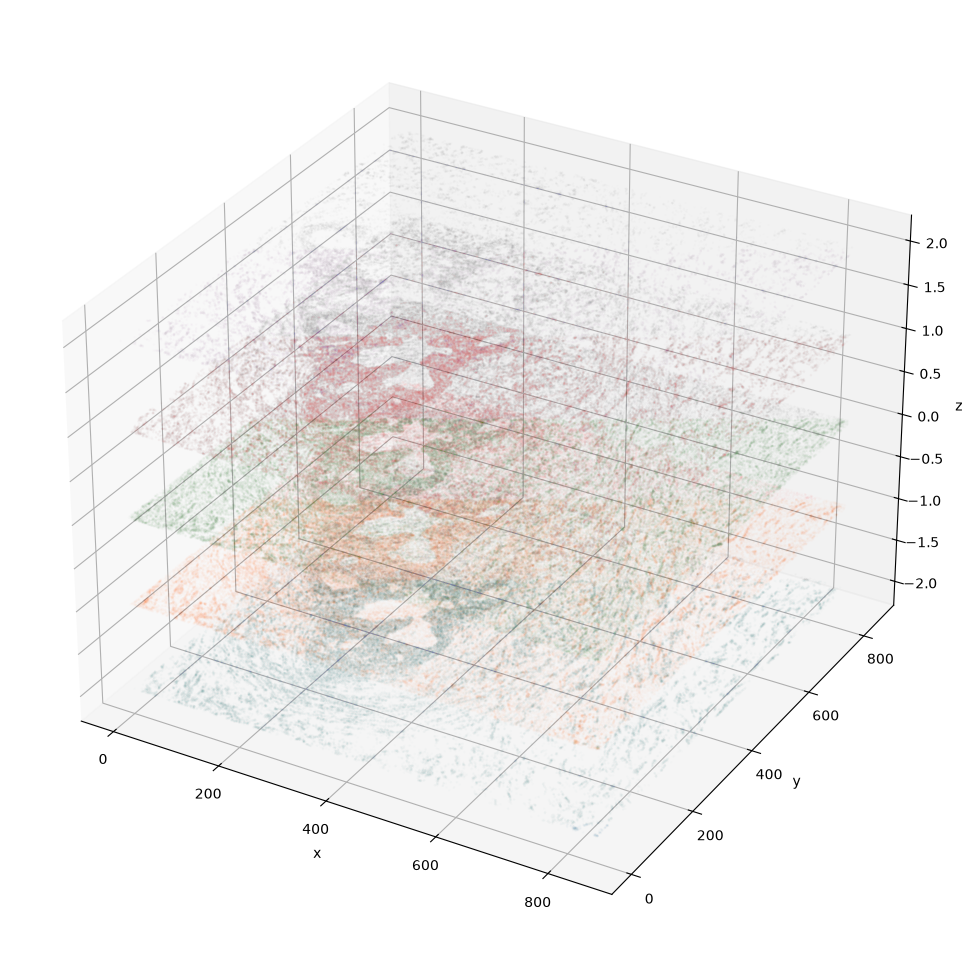

In [49]:
fig = plt.figure(figsize=(10, 10))
ax = fig.add_subplot(111, projection="3d")

transcript_coordinates_df = ovrlp.transcripts.to_pandas()
for i in range(-2, 3):
    subset = transcript_coordinates_df[
        (transcript_coordinates_df['z'] - transcript_coordinates_df['z_center']).between(i, i + 1)
    ]
    # downsample the number of transcripts if it takes too long or you end up in memory issues
    # subset = subset[::10]

    ax.scatter(subset["x"], subset["y"], i, s=1, alpha=0.1)

ratio = transcript_coordinates_df["x"].max() / transcript_coordinates_df["y"].max()
ax.set_box_aspect([ratio, 1, 0.75])
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("z")
plt.tight_layout(pad=2) 
plt.show()
plt.close()

As you can see, it is hard to tell what the plot is showing with the cropped data, thus let us take a look at the full data set.

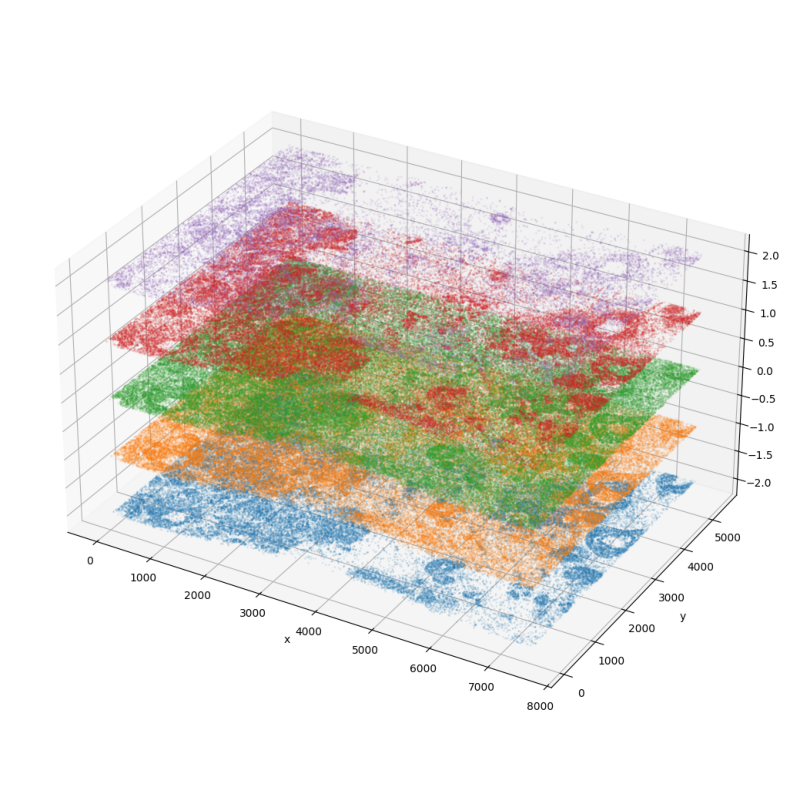

In [50]:
# We will showcase now the full dataset.
plt.figure(figsize=(10, 10))
img = mpimg.imread('../../../Xenium_FFPE_Human_Breast_Cancer_Rep1_outs/doubletqc/scatter_signal_integrity_3d.png')
plt.imshow(img)
plt.axis("off")
plt.show()

This plot displays each transcript by their x, y, and z coordinates. 
Each z coordinate is highlighted with a different color.

As visible in the upper-right corner, the top and bottom z-levels show similar but not identical transcript patterns. 
The lower layer displays a more distinct tissue structure, whereas the top layer is barely visible.
This highlights that the transcript landscape can vary across the thickness of the tissue section.

Next, we will investigate a doublet metric referred to as **vertical signal integrity (VSI)** by the authors of the doublet detection tool.

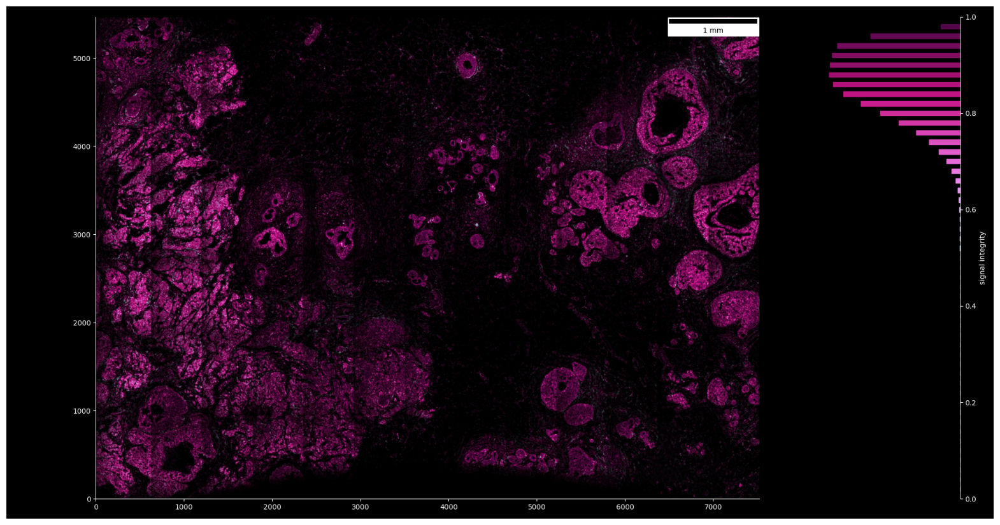

In [51]:
fig = ovrlpy.plot_signal_integrity(ovrlp, signal_threshold=signal_threshold)
plt.tight_layout()
# plt.show() # --> use this so you can see the results for the downsamples data
plt.close()

# We will showcase now the full dataset.
plt.figure(figsize=(20, 20))
img = mpimg.imread('../../../Xenium_FFPE_Human_Breast_Cancer_Rep1_outs/doubletqc/spatial_signal_integrity_map.png')
plt.imshow(img)
plt.axis("off")
plt.show()

Keep in mind we are showing here the full dataset!

The ovrlpy tool works by comparing the transcript landscape between the top and bottom z-levels.
A high VSI value (close to 1.0) indicates strong similarity between these layers, while a lower value (brightes spots), below a defined threshold, suggests potential doublet events, as the top and bottom layers display different transcriptional patterns.
On the left side of the slide, we can clearly observe tissue regions that may represent potential doublets.

Next we will zoom in, and plot an example of a potential doublet region.

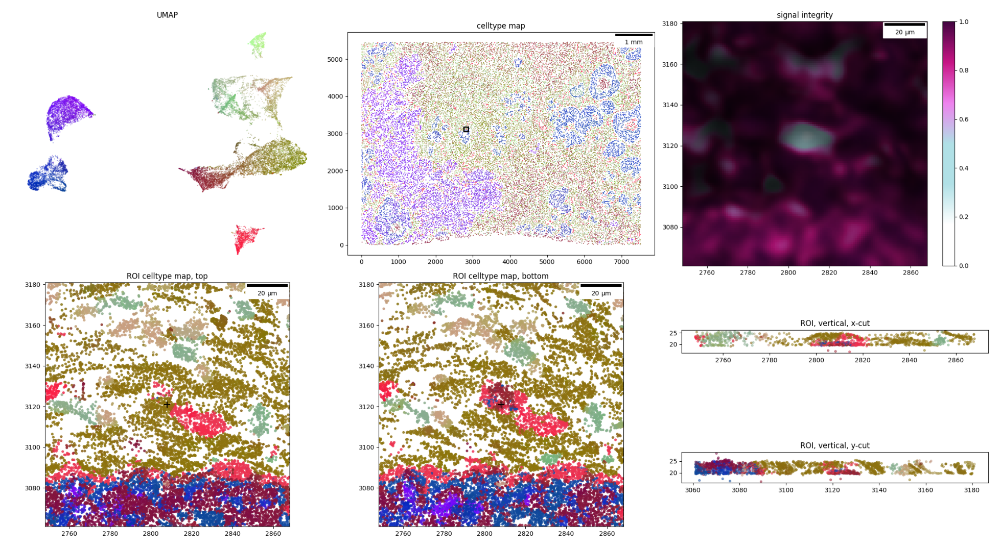

In [52]:
# we will visualize just one example of a doublet
if ( len(doublet_df) < num_doublet ):
        num_doublet = len(doublet_df)

for i in range(0, num_doublet):

    doublet_case = i
    x, y = doublet_df.loc[doublet_case, ["x", "y"]]
    fig = ovrlpy.plot_region_of_interest(
        ovrlp,
        x,
        y,
        window_size=window_sizes[0],
    )
    # plt.show() # --> use this so you can see the results for the downsamples data
    plt.close()

    # zoomed in version
    x, y = doublet_df.loc[doublet_case, ["x", "y"]]
    fig = ovrlpy.plot_region_of_interest(
        ovrlp,
        x,
        y,
        window_size=window_sizes[1],
    )
    # plt.show() # --> use this so you can see the results for the downsamples data
    plt.close()

# We will showcase now the full dataset.
plt.figure(figsize=(25, 20))
img = mpimg.imread('../../../Xenium_FFPE_Human_Breast_Cancer_Rep1_outs/doubletqc/doublet_case_0.png')
plt.imshow(img)
plt.axis("off")
plt.show()

Let us zoom in further on the same region.

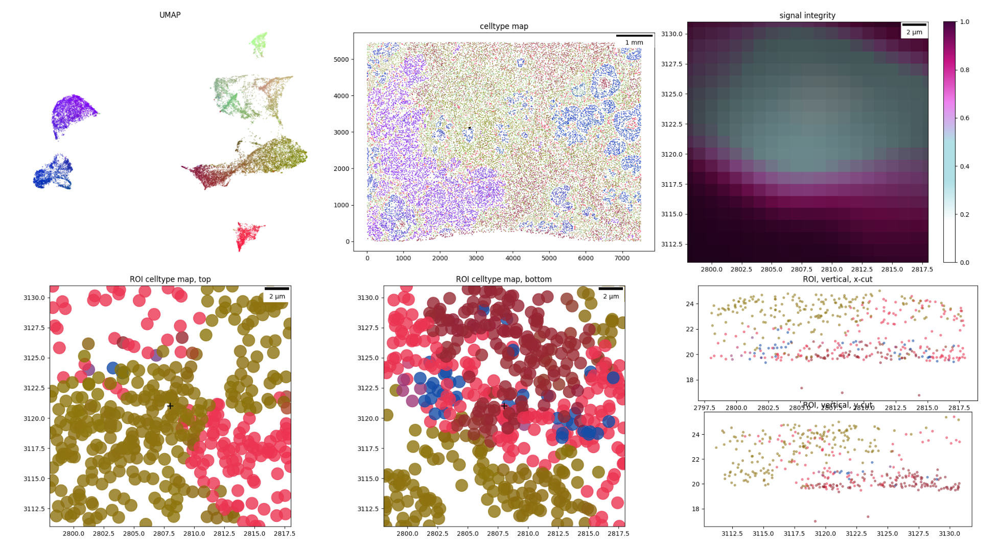

In [53]:
plt.figure(figsize=(25, 20))
img = mpimg.imread('../../../Xenium_FFPE_Human_Breast_Cancer_Rep1_outs/doubletqc/doublet_case_0_zoomed.png')
plt.imshow(img)
plt.axis("off")
plt.show()

Keep in mind we are showing here the full dataset!

The first and second figures show the same doublet region, with the second figure providing a zoomed-in view. 
Each point in each plot (except the signal integrity plot) represents an individual transcript molecule.

Each figure begins with a **UMAP**, colored by ovrlpy components.
The number of ovrlpy components is determined by the number of expected cell types in our annotation.
This means that the colors in the UMAP do **not** directly represent cell types.

The **celltype map** projects the ovrlpy components back into spatial coordinates.
The black rectangle highlights the zoomed in region.

The **signal integrity** plot follows the same format as seen earlier, but is focused on the identified doublet region.
Finally, the **ROI plots** show the transcript landscape at the top and bottom z-levels, as well as slices along the x- and y-axes.
The signal appears to originate from two different overlapping ovrlpy components (blue and green, see ROI plots).
Moreover, the transcript landscapes in the top and bottom layers differ, leading to reduced signal integrity and thus justifying the doublet call by ovrlpy.

Of course, examining a single doublet event is not sufficient.
Therefore, we will now visualize all detected events with another cell density plot weighted by the doublet cells.

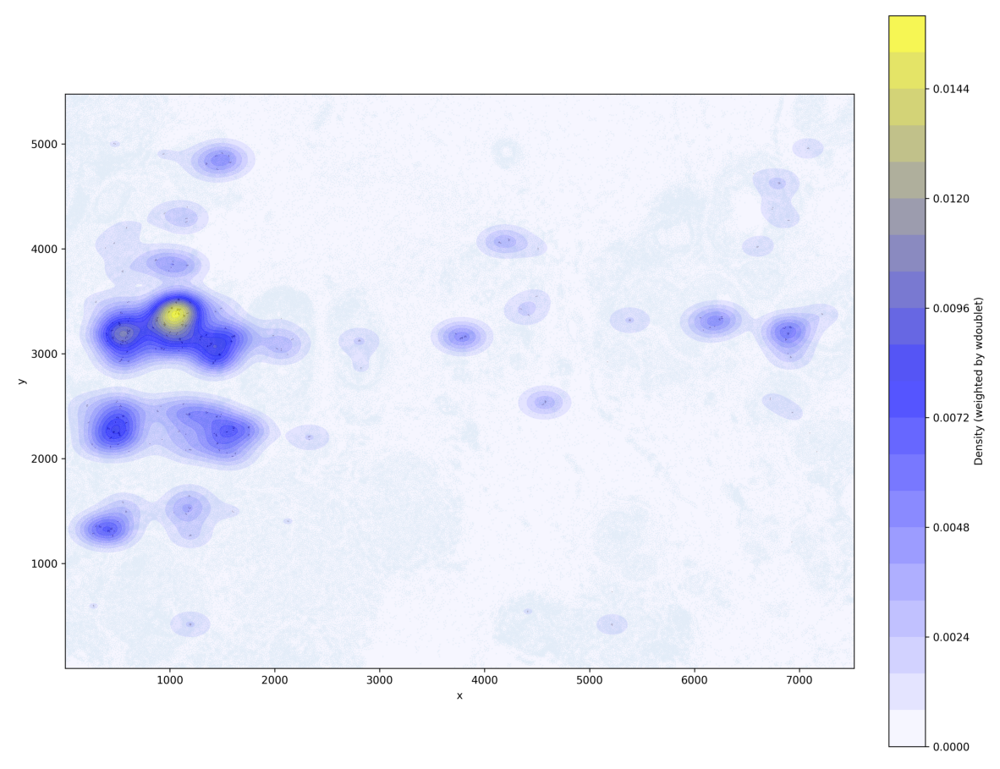

In [54]:
# Link doublet detection back to spatial.
# Based on a distance parameter say if a cell might be a doublet or not.
cell_doublet_df = pd.DataFrame({
    'x': [poly.centroid.x for poly in sdata['cell_boundaries']['geometry']],
    'y': [poly.centroid.y for poly in sdata['cell_boundaries']['geometry']],
    'doublet': [False] * sdata['table'].n_obs,
    'wdoublet': [0] * sdata['table'].n_obs
})

corrected_doublet_df = doublet_df.copy()

# Bring doublets back to the original coordinate system.
corrected_doublet_df['x'] = doublet_df['x'] + min_x
corrected_doublet_df['y'] = doublet_df['y'] + min_y

for i, doublet in corrected_doublet_df.iterrows():
    x1, y1 = doublet['x'], doublet['y']
    distances = np.sqrt((cell_doublet_df['x'] - x1)**2 + (cell_doublet_df['y'] - y1)**2)
    cell_doublet_df.loc[distances <= distance, 'doublet'] = True
    cell_doublet_df.loc[distances <= distance, 'wdoublet'] = 1

# Write into sdata
sdata['table'].obs['doublet'] = np.array(cell_doublet_df['doublet'])
sdata['table'].obs['wdoublet'] = np.array(cell_doublet_df['wdoublet'])

# Plot doublet density
# plot_scatter_density(sdata['table'], 'doublet', 'wdoublet', ['lightblue', 'black'], 'Doublet Density', category=None, pointsize=5.0) # --> use this so you can see the results for the downsamples data
plt.figure(figsize=(15, 15))
img = mpimg.imread('../../../Xenium_FFPE_Human_Breast_Cancer_Rep1_outs/doubletqc/scatterplot_densityplot_doublet.png')
plt.imshow(img)
plt.axis("off")
plt.show()

Keep in mind we are showing here the full dataset!

We identified several doublet regions `cell_doublet_df` where cells may overlap. 
These cells are now labeled as doublets in `sdata['table'].obs['doublet']`.

(advanced-qc-advanced-qc-key-takeaway-3)=
### Ambient RNA detection

Unlike scRNA-seq, ambient RNA in spatial assays can be spatially localized {cite:p}`spat:kwok2025denoising`.
This means that a slide may exhibit random spatial scattering of the same transcript, either locally or across the entire slide.
In addition, spatial technologies such as Xenium rely on the user to define gene panels (e.g. 300-400 gene panels). 
The selection of those genes can dictate the extent of ambient RNA in the slide.

One approach to investigate potential ambient RNA contamination is to calculate Moran’s I (spatial autocorrelation) across all transcripts for each gene. 
We will start with this calculation and then discuss how to interpret the results.

In [55]:
rna = sdata['table']
sc.pp.normalize_total(rna)
sc.pp.log1p(rna)

gene_svariance_moransI_list = []
genes = list(rna.var_names)

def compute_for_gene(gene, rna):
    data = pd.DataFrame({
        'x': rna.obsm['spatial'][:, 0],
        'y': rna.obsm['spatial'][:, 1]
    })
    gdf = gpd.GeoDataFrame(data, geometry=gpd.points_from_xy(data.x, data.y))
    w = Queen.from_dataframe(gdf)
    moran = Moran(rna.X[:, list(rna.var_names).index(gene)].todense(), w, permutations=999)
    return [gene, moran.VI_sim, moran.I]

print(f"[NOTE] Checking {len(genes)} genes")
with concurrent.futures.ThreadPoolExecutor(max_workers=THREADS) as executor:
    futures = [executor.submit(compute_for_gene, gene, rna) for gene in genes]
    with tqdm(total=len(futures), desc="Computing Moran's I", unit="gene") as pbar:
        for future in concurrent.futures.as_completed(futures):
            gene_svariance_moransI_list.append(future.result())
            pbar.update(1)

print("[finish]")

[NOTE] Checking 313 genes


Computing Moran's I: 100%|██████████| 313/313 [01:37<00:00,  3.22gene/s]

[finish]


Now that we have calculated the global Moran’s I for each gene, we will sort the results and plot the 40 genes with the lowest values.

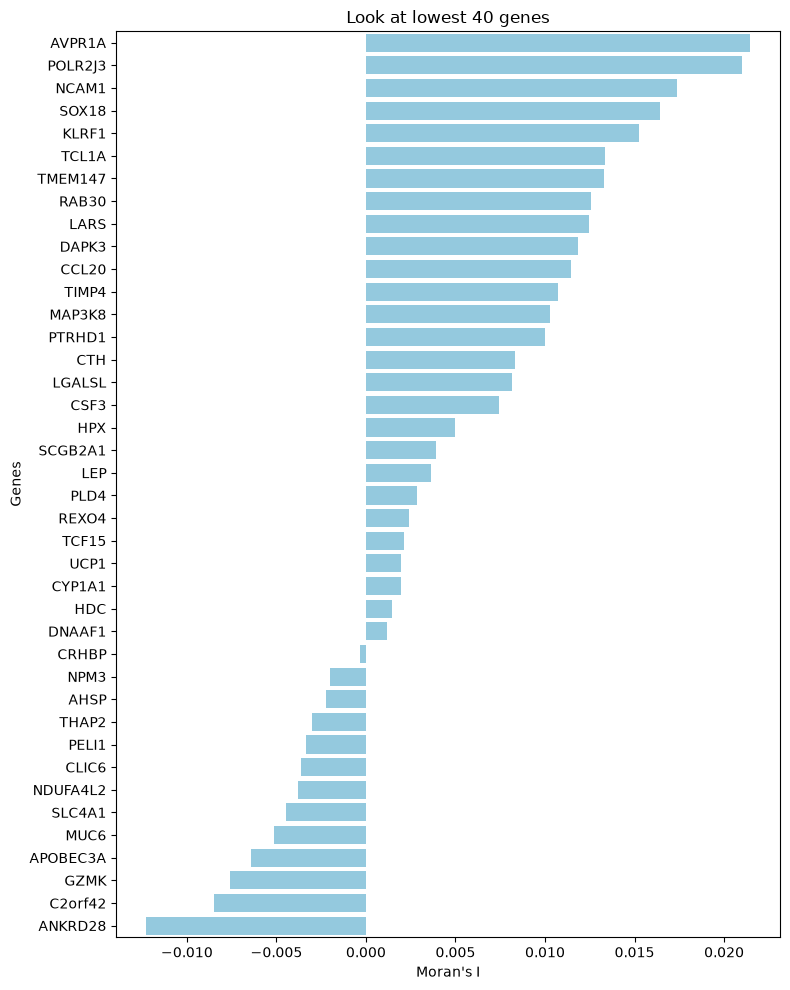

In [56]:
data = pd.DataFrame(gene_svariance_moransI_list)
data.columns = ['genes', 'spatial_variance', 'morans_I']

# Sort the DataFrame by Moran's I in descending order and select the top x genes
top_x_genes = 40
data_sorted = data.sort_values(by='morans_I', ascending=False).tail(top_x_genes)

# Create the bar plot with flipped axes
plt.figure(figsize=(8, len(data_sorted) * 0.25))  # Adjust height based on number of genes
sns.barplot(
    data=data_sorted,
    x="morans_I",
    y="genes",
    orient="h",  # Optional: for clarity
    color="skyblue"  # Optional: for color
)

# Customize labels and title
plt.xlabel("Moran's I")
plt.ylabel("Genes")
plt.title(f"Look at lowest {top_x_genes} genes")
plt.tight_layout()
plt.show()


We plotted 40 genes.
Moran’s I {cite:p}`spat:yamada2024moran` has an approximate range of [−1, 1], with values close to 0 indicating little to no spatial autocorrelation.
As ambient RNA is expected to be relatively uniformly distributed, it should produce random spatial patterns that yield low Moran’s I values close to 0.
Since the dataset was cropped, all genes show low autocorrelation. 
Nonetheless, this demonstration illustrates how the metric can be applied.

Let’s plot a few examples to obtain a clearer visual representation.

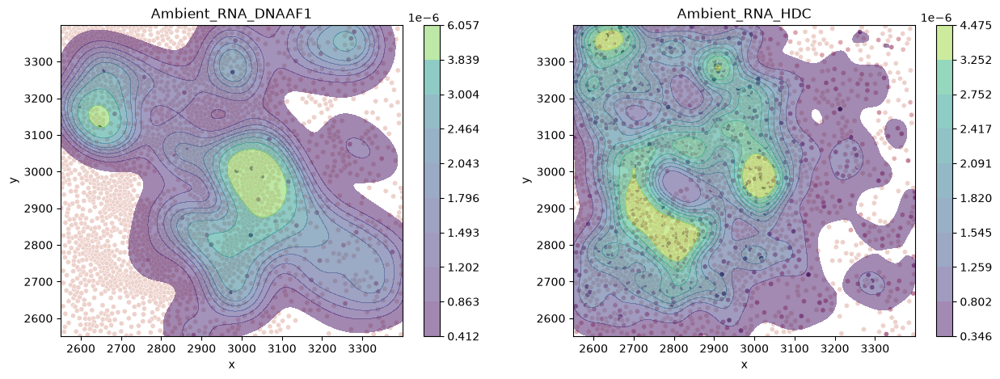

In [ ]:
ambient = dict({'Ambient_RNA': ['DNAAF1', 'HDC']})
helperfuncs.plot_marker_density_in_spatial_context(sdata, ambient)

As shown, the genes *DNAAF1* and *HDC* exhibit very weak signals and are scattered across the slide.
However, since we are working with cropped data, this conclusion may not be reliable.

(advanced-qc-advanced-qc-key-takeaway-4)=
### Negative and Positive Markers

It is important to examine known positive and negative markers to ensure biological credibility.
Positive markers should display spatial enrichment in the expected cell types or tissue regions, often with clear gradients or clustering.
In contrast, negative markers should be absent or only weakly expressed in those same areas.

Let’s first inspect the general expression of known markers for a few cell types.

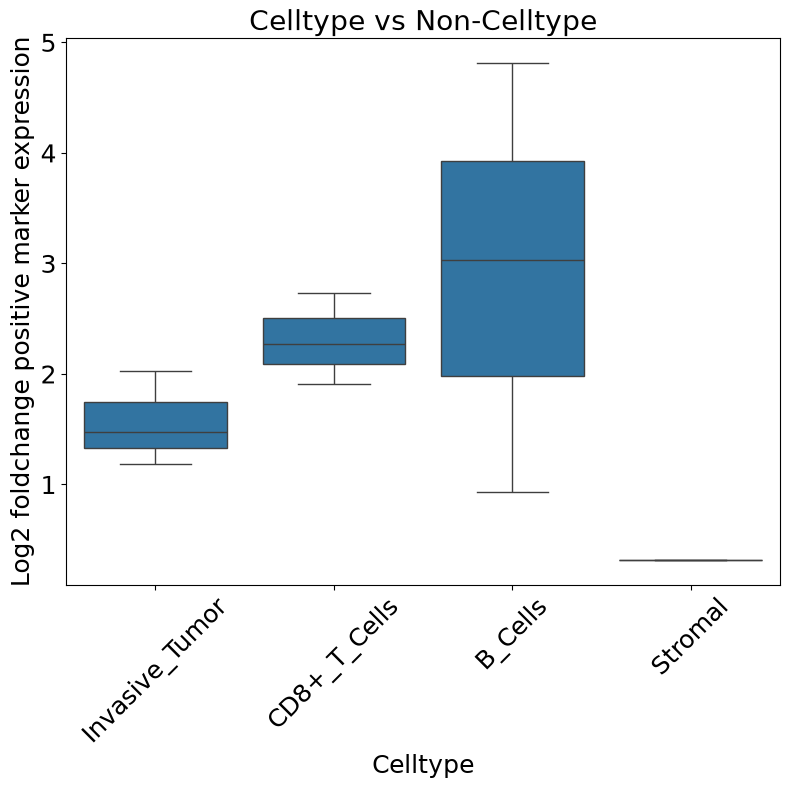

In [ ]:
positive_markers = dict({'Invasive_Tumor': ['GATA3', 'ERBB2', 'EPCAM'],
                        'CD8+_T_Cells': ['CD8A', 'CD3D', 'CD247'],
                        'B_Cells': ['CD19', 'CD79B', 'CD1C'],
                        'Stromal': ['ACTA2']
                        })

helperfuncs.plot_marker_boxplot(sdata, positive_markers, ANNOTATION_KEY, 'positive marker')

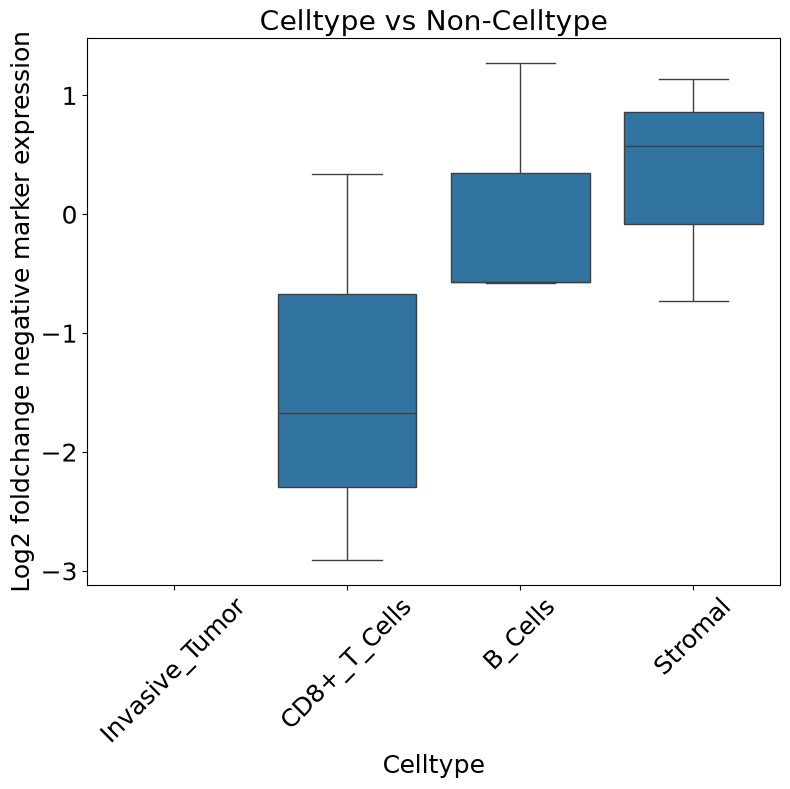

In [ ]:
negative_markers = dict({'Invasive_Tumor': ['KRT14', 'MMP1', 'FOXC2'],
                        'CD8+_T_Cells': ['CD19', 'CD14', 'ITGAM'],
                        'B_Cells': ['CD3D', 'CD4', 'ITGAM'],
                        'Stromal': ['CD3D', 'CD14', 'CD68']
                        })

helperfuncs.plot_marker_boxplot(sdata, negative_markers, ANNOTATION_KEY, 'negative marker')

We can clearly observe higher expression of positive markers for the respective cell types.
    
However, examining marker expression levels alone is not sufficient, we also need to investigate their spatial distribution.
We will focus on the *CD8+ T Cell*.

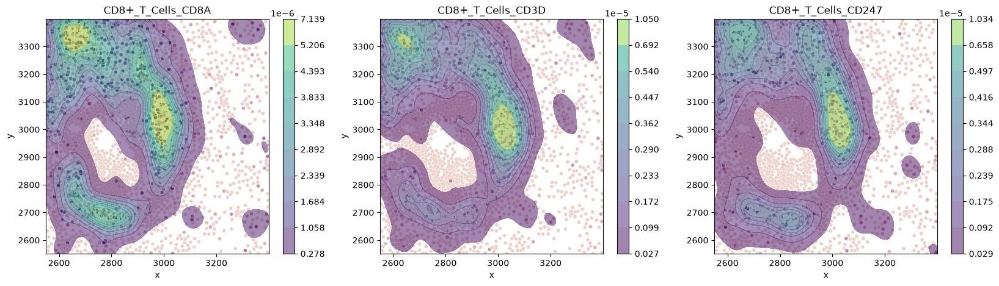

In [ ]:
positive_markers = dict({'CD8+_T_Cells': ['CD8A', 'CD3D', 'CD247']})

helperfuncs.plot_marker_density_in_spatial_context(sdata, positive_markers, (20,5))

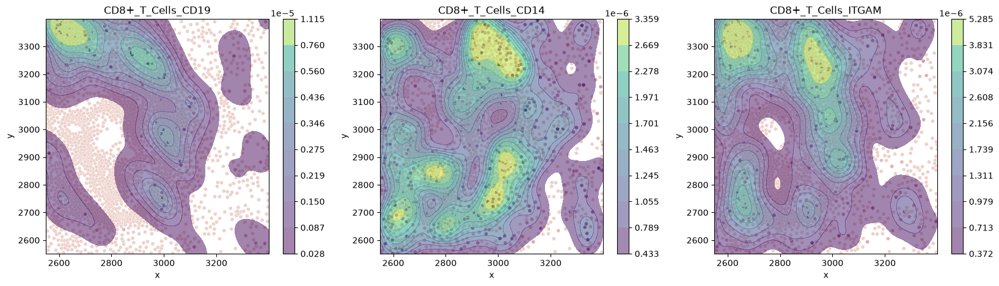

In [ ]:
negative_markers = dict({'CD8+_T_Cells': ['CD19', 'CD14', 'ITGAM']})

helperfuncs.plot_marker_density_in_spatial_context(sdata, negative_markers, (20,5))

By visual inspection, we see that the spatial distributions of the positive markers overlap, while the negative markers *CD14* and *ITGAM* appear more randomly distributed across the slide.
This also supports the previously visualized cell type annotation for CD8+ cells.

(advanced-qc-advanced-qc-key-takeaway-5)=
## Level 2: Segmentation

To evaluate segmentation quality, we can apply concepts from the single-cell field.
To do that, we apply scanpy to our `anndata`.

In [62]:
# Add mitochondrial coverage
rna.var["mt"] = rna.var_names.str.startswith("MT-")

# Add ribosomal coverage
rna.var["ribo"] = rna.var_names.str.startswith("RPS") | rna.var_names.str.startswith("RPL")

sc.pp.calculate_qc_metrics(rna, percent_top=(10, 20, 50, 150), inplace=True)

rna.obs[f'log10_1p_total_counts'] = np.log10(rna.obs['total_counts'] + 1)
rna.obs[f'log10_1p_n_genes_by_counts'] = np.log10(rna.obs['n_genes_by_counts'] + 1)

# This just add 0% mitochondiral and ribosomal coverage if no genes could be found for it.
rna_mt = rna[:,rna.var['mt']]
if ( rna_mt.n_vars == 0 ):
    rna.obs['pct_counts_mt'] = [0.0] * rna.n_obs

rna_rb = rna[:,rna.var['ribo']]
if ( rna_rb.n_vars == 0 ):
    rna.obs['pct_counts_ribo'] = [0.0] * rna.n_obs

### Total counts and gene counts

We expect the total counts distribution to peak around 1–100k, and the gene counts distribution to peak around the number of genes included in the panel. 
Occasionally, bi- or trimodal distributions may appear, indicating low-quality cells, potential segmentation errors, or overlapping cells.

#### Cell area and nucleus area

The cell and nucleus areas should match expectations based on cell morphology. 
Areas that are unusually large or small may point to segmentation problems or issues with tissue preparation.

### Mitochondrial and ribosomal coverage

In our dataset, we do not have mitochondrial (mt) and ribosomal (rb) genes included in the panel.
However, if they are it is useful to examine their distirbutions (sc-best-practices QC chapter).

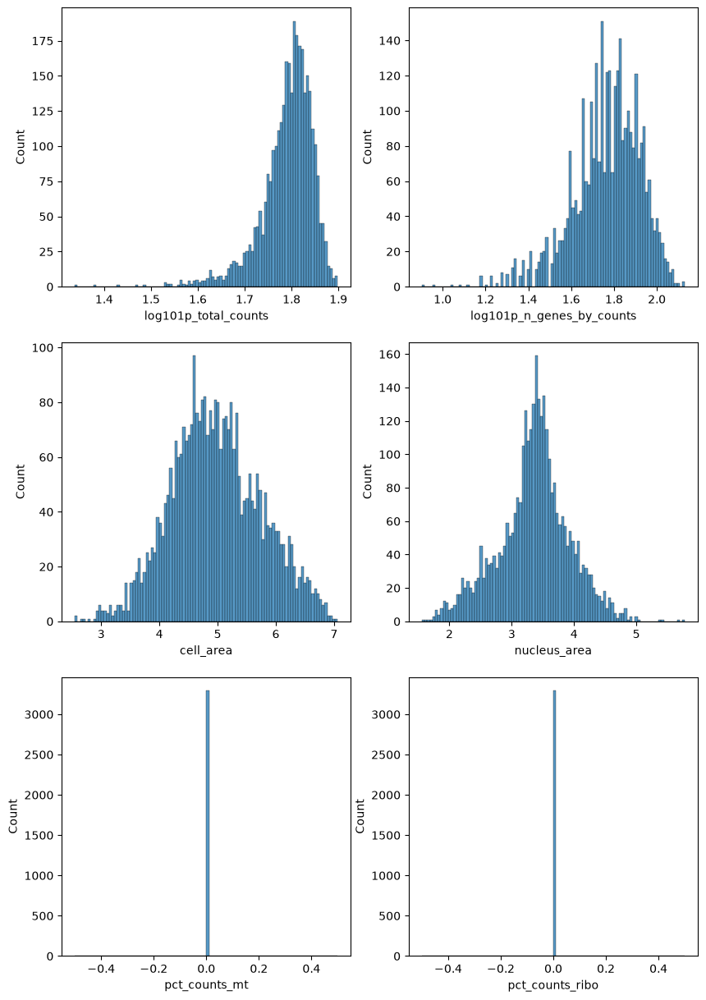

In [63]:
fig, axes = plt.subplots(3, 2, figsize=(10, 15))
p1 = sns.histplot(rna.obs['log10_1p_total_counts'], bins=100, kde=False, ax=axes[0,0])
# axes[0,0].set_title("log1p total counts")
p2 = sns.histplot(rna.obs['log10_1p_n_genes_by_counts'], bins=100, kde=False, ax=axes[0,1])
# axes[0,1].set_title("log1p gene counts")
p3 = sns.histplot(np.log1p(rna.obs['cell_area']), bins=100, kde=False, ax=axes[1,0])
# axes[1,0].set_title("cell area")
p4 = sns.histplot(np.log1p(rna.obs['nucleus_area']), bins=100, kde=False, ax=axes[1,1])
# axes[1,1].set_title("nucelus area")
p5 = sns.histplot(rna.obs['pct_counts_mt'], bins=100, kde=False, ax=axes[2,0])
# axes[2,0].set_title("cell area")
p6 = sns.histplot(rna.obs['pct_counts_ribo'], bins=100, kde=False, ax=axes[2,1])
# axes[2,1].set_title("nucelus area")
plt.show()

(advanced-qc-advanced-qc-key-takeaway-6)=
## Level 3: Image

### Polygons

Image segmentation can occasionally produce invalid cell geometries.
We will examine an example shortly.
While such cases may not always occur, it is good practice to perform a sanity check to identify any cells or nuclei with invalid geometries.

We will use the function `is_valid` from shapely.
Since we are dealing with polygons, a geometry is valid if the following conditions hold (see [The Shapely User Manual](https://shapely.readthedocs.io/en/2.1.0/manual.html) and [shapely.Polygon](https://shapely.readthedocs.io/en/stable/reference/shapely.Polygon.html)):

- The rings of a valid polygon may not cross each other but may touch at a single point.
- A polygon has a non-zero area and non-zero length if it is not empty.
- A valid polygon may not have any overlapping exterior or interior rings.
This means that an interior ring must be completely enclosed by the exterior ring and may touch the exterior ring at no more than one point.

Ultimately, an invalid polygon is always a sign of improper segmentation.

In [64]:
faulty_geometries = {}
for obj_type in ['cell', 'nucleus']:
    geometries = np.array(sdata[f'{obj_type}_boundaries']['geometry'])
    sdata['table'].obs[f'valid_{obj_type}_geometry'] = [True if x.is_valid else False for x in geometries]
    sdata['table'].obs[f'wvalid_{obj_type}_geometry'] = [0 if x.is_valid else 1 for x in geometries]
    faulty_geometries[obj_type] = []

    num_invalid_examples = 0
    for i, obj in enumerate(geometries):
        if not obj.is_valid and num_invalid_examples < 10:
            print(f'Invalid {obj_type} with id {i} found')
            x, y = obj.exterior.xy
            faulty_geometries[obj_type].append((i,x,y))
            num_invalid_examples += 1

Invalid cell with id 332 found
Invalid cell with id 2181 found
Invalid nucleus with id 940 found
Invalid nucleus with id 1198 found
Invalid nucleus with id 1764 found
Invalid nucleus with id 2012 found


As shown, we identified 2 invalid cells and 4 invalid nuclei.
To better illustrate this, let’s visualize the affected cells and nuclei.

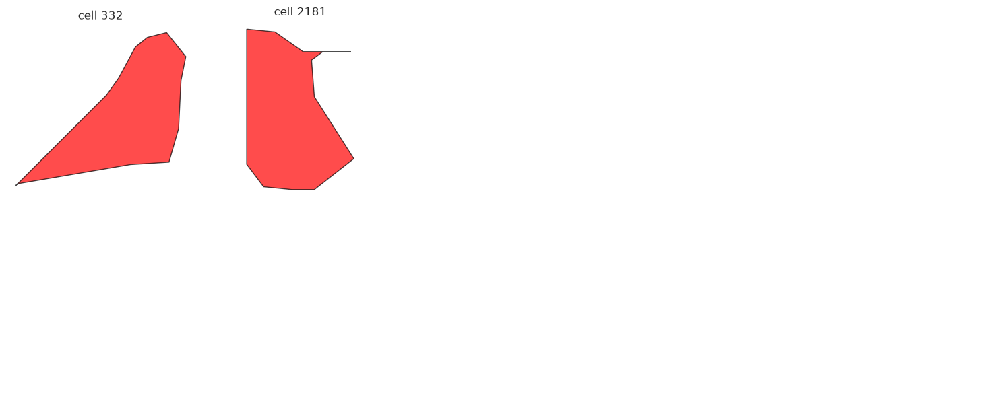

[WARNING] Failed to plot density with KDE probably because not enough data points for your chosen density category: cannot do a non-empty take from an empty axes.
Just plotting scatter plot.


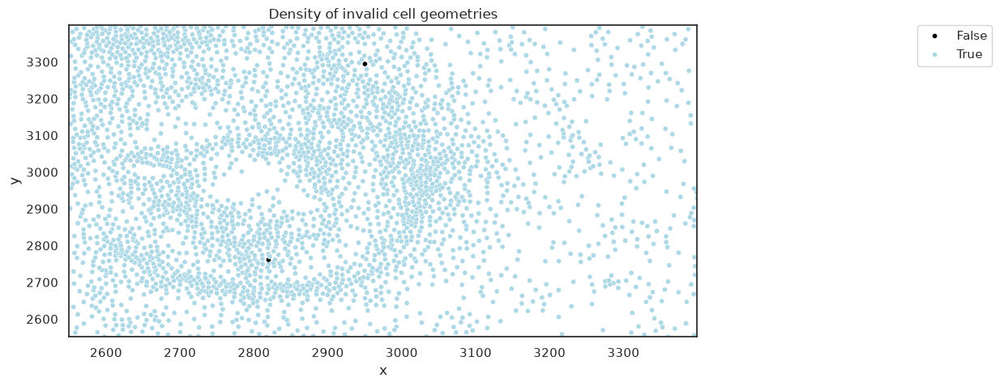

In [ ]:
obj_type = 'cell'
sns.set_theme(style="white")
n = len(faulty_geometries[obj_type])

fig, axes = plt.subplots(2, 5, figsize=(15, 6))
axes = np.array(axes).reshape(-1)

for ax, (idx, x, y) in zip(axes, faulty_geometries[obj_type]):
    ax.fill(x, y, alpha=0.7, facecolor='red', edgecolor='black')
    ax.set_aspect('equal')
    ax.axis('off')
    ax.set_title(f"{obj_type} {idx}")

for ax in axes[n:]:
    ax.axis('off')

plt.tight_layout()
plt.show()

helperfuncs.plot_spatial_density_of_category(sdata['table'], f'valid_{obj_type}_geometry', f'wvalid_{obj_type}_geometry', 
                     ['black', 'lightblue'], f'Density of invalid {obj_type} geometries', category=None, pointsize=20.0)

Here we can see the locations of the invalid geometries.
Since only two invalid cell geometries were detected, no specific spatial pattern can be concluded.

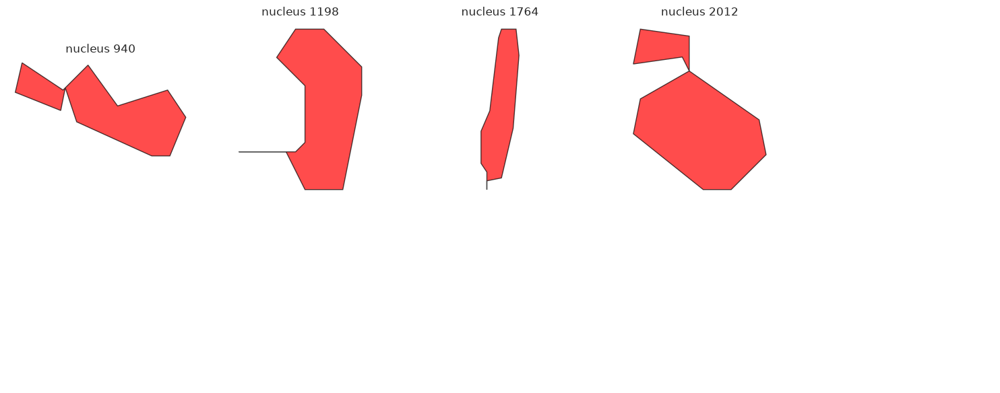

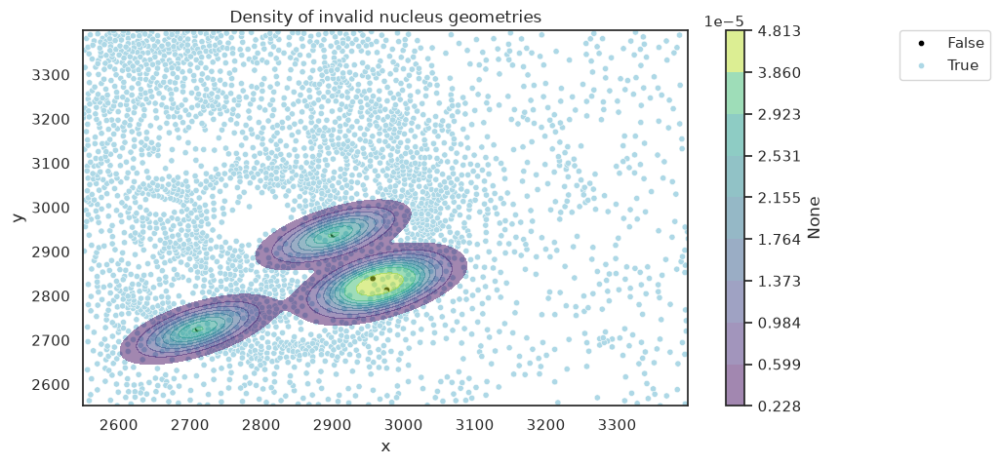

In [ ]:
obj_type = 'nucleus'
sns.set_theme(style="white")
n = len(faulty_geometries[obj_type])

fig, axes = plt.subplots(2, 5, figsize=(15, 6))
axes = np.array(axes).reshape(-1)

for ax, (idx, x, y) in zip(axes, faulty_geometries[obj_type]):
    ax.fill(x, y, alpha=0.7, facecolor='red', edgecolor='black')
    ax.set_aspect('equal')
    ax.axis('off')
    ax.set_title(f"{obj_type} {idx}")

for ax in axes[n:]:
    ax.axis('off')

plt.tight_layout()
plt.show()

helperfuncs.plot_spatial_density_of_category(sdata['table'], f'valid_{obj_type}_geometry', f'wvalid_{obj_type}_geometry', 
                     ['black', 'lightblue'], f'Density of invalid {obj_type} geometries', category=None, pointsize=20.0)

From the geometries, we can see why these polygons were flagged as invalid. 
It is best to correct or filter out such cells and nuclei to prevent errors in downstream analyses.

To address this, we will correct the geometries using the convex_hull method.

In [68]:
for obj_type in ['cell', 'nucleus']:
    geometries = np.array(sdata[f'{obj_type}_boundaries']['geometry'])
    for i, obj in enumerate(geometries):
        if( not obj.is_valid ):
            geometries[i] = obj.convex_hull
    sdata[f'{obj_type}_boundaries']['geometry'] = geometries

Now that we have corrected the geometries, we need to recheck them.

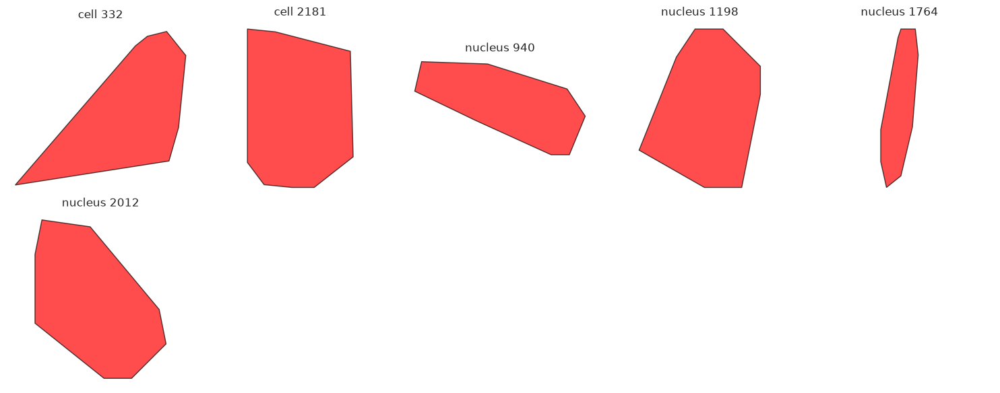

In [69]:
corrected_geometries = []
for obj_type in ['cell', 'nucleus']:
    geometries = np.array(sdata[f'{obj_type}_boundaries']['geometry'])
    for tup in faulty_geometries[obj_type]:
        obj = geometries[tup[0]]
        x, y = obj.exterior.xy
        corrected_geometries.append((tup[0], x, y, obj_type))


fig, axes = plt.subplots(2, 5, figsize=(15, 6))
axes = np.array(axes).reshape(-1)

for ax, (idx, x, y, obj_type) in zip(axes, corrected_geometries):
    ax.fill(x, y, alpha=0.7, facecolor='red', edgecolor='black')
    ax.set_aspect('equal')
    ax.axis('off')
    ax.set_title(f"{obj_type} {idx}")

for ax in axes[n:]:
    ax.axis('off')

plt.tight_layout()
plt.show()

(advanced-qc-advanced-qc-key-takeaway-7)=
### Background Intensity

Identifying background pixel intensity can help detect areas affected by blur, out-of-focus regions, or other artifacts that result in low-intensity signals.
To do this, we will apply Otsu’s method {cite:p}`spat:otsu1979threshold`, which automatically determines the optimal intensity threshold that separates an image into foreground and background by maximizing the between-class variance (or equivalently, minimizing the within-class variance) of pixel intensities.

Compared to simple histogram-based thresholding, Otsu’s method offers several advantages:
- No manual threshold selection is required.
- The threshold adapts to the actual pixel intensity distribution.
- It performs well even when the background peak is not clearly defined or overlaps with the foreground.

First, we will plot the intensity distribution to obtain an initial estimate of the expected background intensity.

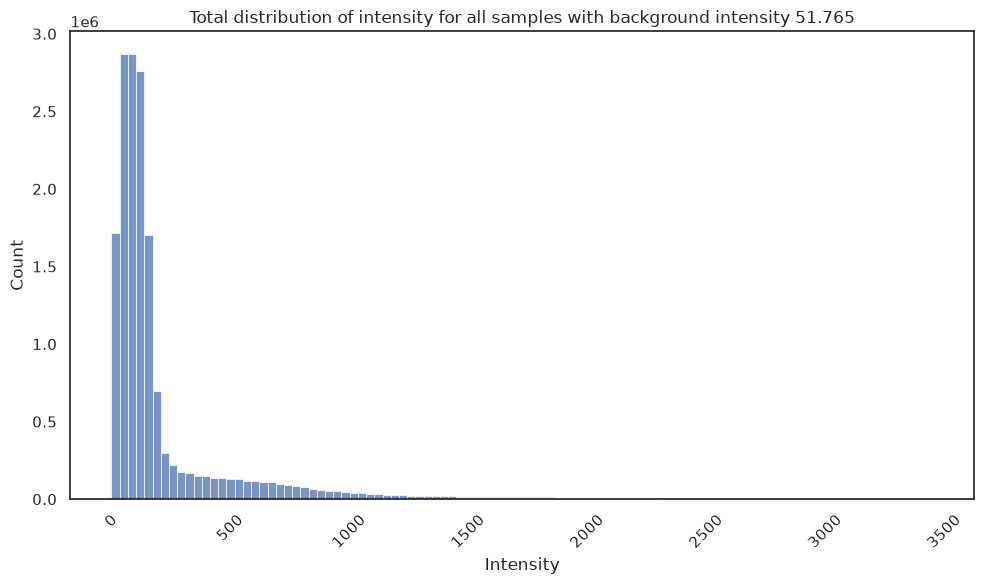

In [70]:
nbins = 100
hist, bin_edges = np.histogram(sdata[IMAGE][RESOLUTION].image.values.flatten(), bins=nbins)
max_bin_index = np.argmax(hist)
max_bin_range = (bin_edges[max_bin_index], bin_edges[max_bin_index + 1])
background_intensity = np.round(np.mean(max_bin_range), 3)
bins = np.round(0.5 * (bin_edges[:-1] + bin_edges[1:]))

plt.figure(figsize=(10, 6))
sns.histplot(sdata[IMAGE][RESOLUTION].image.values.flatten(), bins=nbins)
plt.title(f"Total distribution of intensity for all samples with background intensity {background_intensity}")
plt.xlabel("Intensity")
plt.ylabel("Count")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

As shown in the plot title, our empirical threshold is ~51.765.

Next, we will apply Otsu thresholding.

Optimal own threshold: 51.0
Optimal Otsu threshold: 572.0


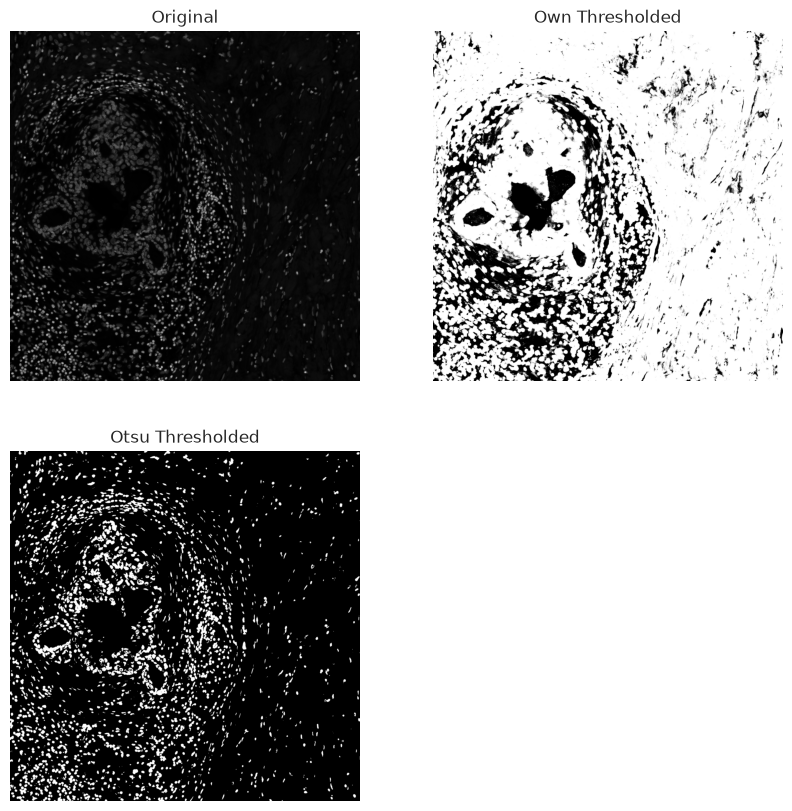

In [71]:
# Otsu's thresholding after Gaussian filtering
img = sdata[IMAGE][RESOLUTION].image.values[0]
threshold,binary = cv2.threshold(img, background_intensity, 255, cv2.THRESH_BINARY)

blur = cv2.GaussianBlur(img,(5,5),0)
threshold_otsu,binary_otsu = cv2.threshold(blur,0,255,cv2.THRESH_BINARY+cv2.THRESH_OTSU)

print(f"Optimal own threshold: {threshold}")
print(f"Optimal Otsu threshold: {threshold_otsu}")

# Show result
plt.figure(figsize=(10, 10))
plt.subplot(2, 2, 1)
plt.title("Original")
plt.axis('off')
plt.imshow(img, cmap='gray')

plt.subplot(2, 2, 2)
plt.title("Own Thresholded")
plt.axis('off')
plt.imshow(binary, cmap='gray')

plt.subplot(2, 2, 3)
plt.title("Otsu Thresholded")
plt.axis('off')
plt.imshow(binary_otsu, cmap='gray')

plt.show()

Using Otsu’s thresholding, we created a binary image that highlights the pixels contributing to biological patterns.

(advanced-qc-advanced-qc-key-takeaway-8)=
### H&E artefacts

For H&E images, several tools exist that can detect artefacts such as tissue folds and bubbles. 
However, these tools are typically optimized for H&Es derived directly from pathological slides.

When testing tools such as [GrandQC](https://github.com/cpath-ukk/grandqc) and [HistoQC](https://github.com/choosehappy/HistoQC?tab=readme-ov-file), we found that they struggle to detect artefacts in post-ISH/ISS H&E stains.
Here, we showcase [GrandQC](https://github.com/cpath-ukk/grandqc) applied to the H&E-ome.tif image from our dataset.
We selected GrandQC because it showed promising results in H&E artefact classification.
In addition, it is relatively fast and comes with an expert-curated training dataset.

#### Issues with GrandQC

The main drawback, and a potential source of error, lies in the GrandQC codebase.
The tool is not available as an installable package, so users must adapt the provided shell scripts to apply the trained model, that is why we can only show the resulting figures.
Moreover, we had to further modify the code to handle the H&E slide format used by 10x, as GrandQC expects input data in a specific format and otherwise throws errors.

#### Remark

Please note that the artefact mask generated from H&E images is not directly applicable to your data.
Artefact detection should instead be treated as a guide to potentially problematic regions.
To make practical use of the mask, one would need to align the H&E image with the in-situ visualization image provided by the ISS/ISH system.

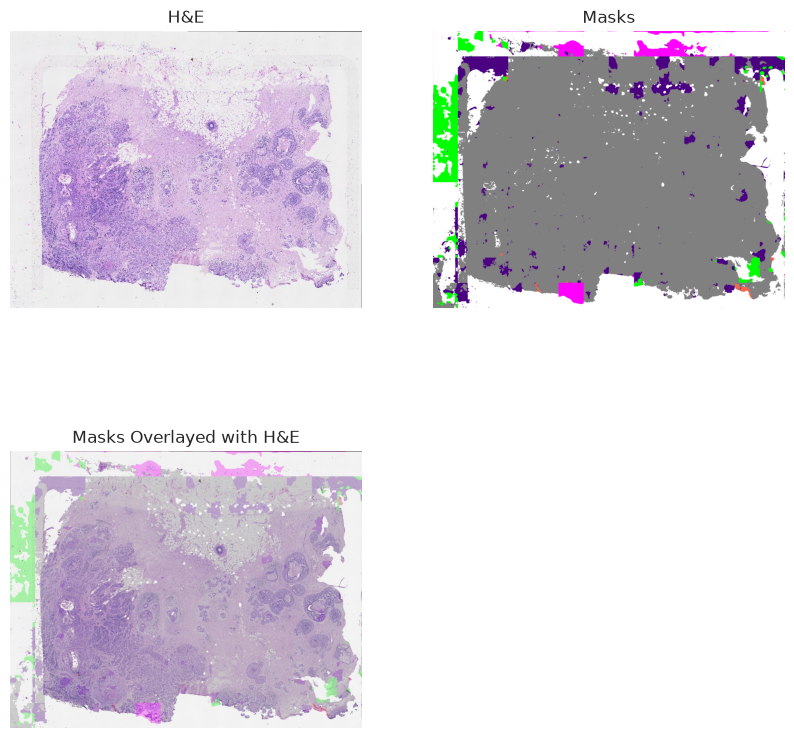

In [72]:
# H&E
plt.figure(figsize=(10, 10))
plt.subplot(2, 2, 1)
img = mpimg.imread('../../../Xenium_FFPE_Human_Breast_Cancer_Rep1_outs/grandqc_results/tis_det_thumbnail/Xenium_FFPE_Human_Breast_Cancer_Rep1_he_image.ome.tif.jpg')
plt.imshow(img)
plt.title("H&E")
plt.axis('off')

# Aretefact maps
plt.subplot(2, 2, 2)
img = mpimg.imread('../../../Xenium_FFPE_Human_Breast_Cancer_Rep1_outs/grandqc_results/maps_qc/Xenium_FFPE_Human_Breast_Cancer_Rep1_he_image.ome.tif_map_ALL.png')
plt.imshow(img)
plt.title("Masks")
plt.axis('off')

# Overlay
plt.subplot(2, 2, 3)
img = mpimg.imread('../../../Xenium_FFPE_Human_Breast_Cancer_Rep1_outs/grandqc_results/overlays_qc/Xenium_FFPE_Human_Breast_Cancer_Rep1_he_image.ome.tif_overlay_QC.jpg')
plt.imshow(img)
plt.axis('off')
plt.title("Masks Overlayed with H&E")
plt.show()

* gray = no artifact
* rose = air / edge
* red = pen marking
* dark blue = out-of-focus
* green = tissue fold
* bright green (orange) = dark spot / foreign / unkown

GrandQC identified several candidate artefact regions; however, it also falsely detects tissue beyond the slide boundaries. 
Because it uses patch-based inference, the detected regions sometimes have unnaturally straight, block-like edges.

The code below is to save the adata object on our database.

In [ ]:
af = ln.Artifact.from_anndata(
    adata,
    key="spatial/preprocessing/xenium_breast_cancer.zarr",
    description="sdata after advanced quality control and filtering of invalid geometries and doublets",
).save()
af

## Contributors

We gratefully acknowledge the contributions of:

### Authors
Florian Heyl

### Reviewers
Francesca Drummer